<a href="https://colab.research.google.com/github/Overduz003/GoogleCollab_Algorithms/blob/main/DjikstraAlgorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import heapq



**Funcion Djikstra**


In [ ]:

def dijkstra(map, start, goal):

    movimientos = [(0, 1), (1, 0), (0, -1), (-1, 0)]
    distancia = {start: 0} #Guarda el mejor costo conocido para llegar a cada poscion
    anteriores = {} #Guarda de donde venimos (las posiciones que llevamos)
    recorrido = [(0, start)] #cola de rutas  (vecinos / rutas posibles ) con su costo acumulado --> heapq.heappop(recorrido) toma la desicion en base a la ruta de menor costo
    path = []

    # Obtener la posicion que tenga el menor costo
    while recorrido:
        costo_actual, actual = heapq.heappop(recorrido)

        # Ignorar posiciones que ya tengan un costo mayor
        if costo_actual > distancia[actual]:
            continue

        # Llegamos al objetivo, terminamos
        if actual == goal:
            break

        # Actual y movimiento son tuplas

        # Empezamos con el movimiento
        for movimiento in movimientos:       #                 0 1                0 1
            fila = actual[0] + movimiento[0] #tuplas -> actual(1,2) + movimietnto(1,0)
            columna = actual[1] + movimiento[1] #Movernos entre filas y columnas

            vecino = (fila, columna)

            if (0 <= fila < map.shape[0] and 0 <= columna < map.shape[1]): #No salirnos de mapa 0,5 6x6

                if map[fila, columna] == 0: #detectar obstaculos 1= Obstaculo 0= camino libre
                    nuevo_costo = costo_actual + 1 # costo acumulado

                    if vecino not in distancia or nuevo_costo < distancia[vecino]: #verificacion sobre si el vecino ya ha sido explorado o si su costo es menor al registrado
                        distancia[vecino] = nuevo_costo #Sacar el nuevo costo del vecino
                        anteriores[vecino] = actual #De donde venimos

                        heapq.heappush(recorrido, (nuevo_costo, vecino))

    # Reconstruir el camino
    if goal in distancia:

        actual = goal

        while actual != start:
            path.append(actual)
            actual = anteriores[actual]

        path.append(start)

        # Invertir para comenzar desde start
        path.reverse()

    # Return path
    return path


**Seleccion de Mapa**

In [ ]:
TipoMap= 2 #1 o 2

**Creacion de mapa**

In [ ]:
# Define map and start and goal
if TipoMap==1:
  # Define map
  map = np.array([
      [0, 1, 0, 0, 0, 1],
      [0, 0, 0, 1, 0, 1],
      [0, 1, 0, 1, 0, 0],
      [0, 0, 0, 0, 0, 1],
      [0, 1, 0, 1, 1, 1],
      [0, 1, 0, 0, 0, 0],
  ])

  # Define start and goal
  start = (0, 0)  # Starting point
  goal  = (5, 5)  # Goal point

elif TipoMap==2:
  map = np.array([
      [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
      [1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1],
      [1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1],
      [1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1],
      [1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1],
      [1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1],
      [1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1],
      [1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1],
      [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1],
      [1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1],
      [1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1],
      [1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1],
      [1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1],
      [1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1],
      [1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
      [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
  ])

  # Define start and goal
  start = (1, 1)  # Starting point
  goal  = (14, 14) # Goal point}


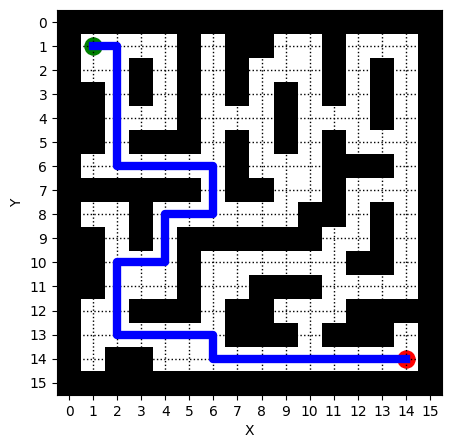

In [ ]:
# Find the shortest path
path = dijkstra(map, start, goal)

# Plot the map
plt.figure(figsize=(5, 5))
plt.imshow(map, cmap='gray_r')

# Plot start and goal
plt.scatter(start[1], start[0], color='green', s=150, label='Start')
plt.scatter(goal[1], goal[0], color='red', s=150, label='Goal')

# Plot the path
if path:
    path_x, path_y = zip(*path)
    plt.plot(path_y, path_x, color='blue', linewidth=6, label='Path')

# Set params
plt.xlabel('X')
plt.ylabel('Y')

plt.xticks(range(0,map.shape[0]))
plt.yticks(range(0,map.shape[1]))

plt.grid(color='k', linestyle=':', linewidth=1)
plt.show()